In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Q1
The goal of this and the next two exercises is to explore the
units of the pdfs provided by the scipy library.

In [40]:
x = np.linspace(-4, 4, 400)

y_1 = stats.norm.pdf(x)
print(np.sum(y_1))

dx = x[1] - x[0]
integral = dx * y_1
print(f"{np.sum(integral):.3f}")

49.87197283513352
1.000


It should sum to 1!
Here is the deal: the area under the pdf (the integral) should sum up to 1, not the y values.
The integral is sum(y) * dx.

# Q2

In [42]:
x = np.linspace(-2, 2, 300)
y = stats.norm.pdf(x)

dx = x[1] - x[0]
y_2 = dx * y
print(f"{np.sum(y_2):.3f}")

0.955


- "Uh oh. It’s not 1. Instead, it is .955. Why does this happen?"
- "Another normalization method: Instead of scaling by dx, di-
vide the "raw" pdf (that is, the output of stats.norm.pdf or
dnorm) by its empirical sum. This trivially forces the function
to sum to 1 and is called "unit-sum" normalization."

In [43]:
y /= sum(y)
print(f"{sum(y):.3f}")

1.000


- "The reason why the normalized pdf summed to
1 in the previous exercise but .955 in this exercise is that the
analytical pdf integrates to 1 in the range of −∞ to +∞. When
using any finite range, the integral will be slightly less than 1.
In fact, if you print out the sum of the pdf from Exercise 1
to 9 digits after the decimal point, you will find that it sums
to .999939305, which is rounded up to 1 with the formatting
I specified. Same story for the pdf from Exercise 2 but the
effect is more extreme."
- "The pdfs have different amplitudes because the x-
axis grid resolutions are different, which means you’ve divided
by different numbers."
- "Which one is correct?
Answer: All of them. They are all correct. The probability
values change as a function of the resolution, for the same
reason that a die landing on "1" has probability 16.67% for a
6-sided die and 8.33% for a 12-sided die. As the set of possible
outcomes waxes, the probability of any individual outcome
wanes."

# Q3

1.000
1.000


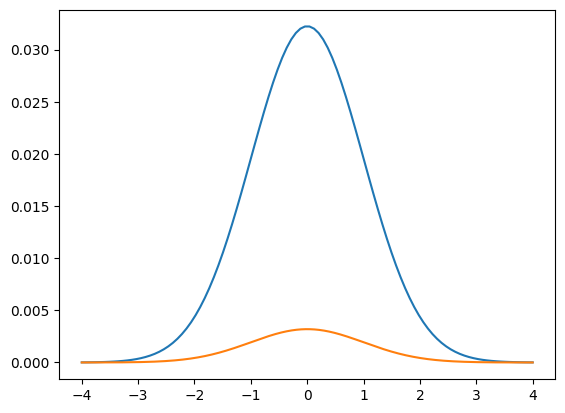

In [44]:
x1 = np.linspace(-4, 4, 100)
x2 = np.linspace(-4, 4, 1000)

y1 = (x1[1] - x1[0]) * stats.norm.pdf(x1)
y2 = (x2[1] - x2[0]) * stats.norm.pdf(x2)

print(f"{sum(y1):.3f}")
print(f"{sum(y2):.3f}")

plt.plot(x1, y1)
plt.plot(x2, y2)
plt.show()

# Q4
"Let’s switch from pdfs to cdfs. It's claimed that the cdf of a prob-
ability distribution is the cumulative sum of the pdf. You can
already infer from the previous exercises that the cumulative
sum over the "raw" pdf will be larger than 1.

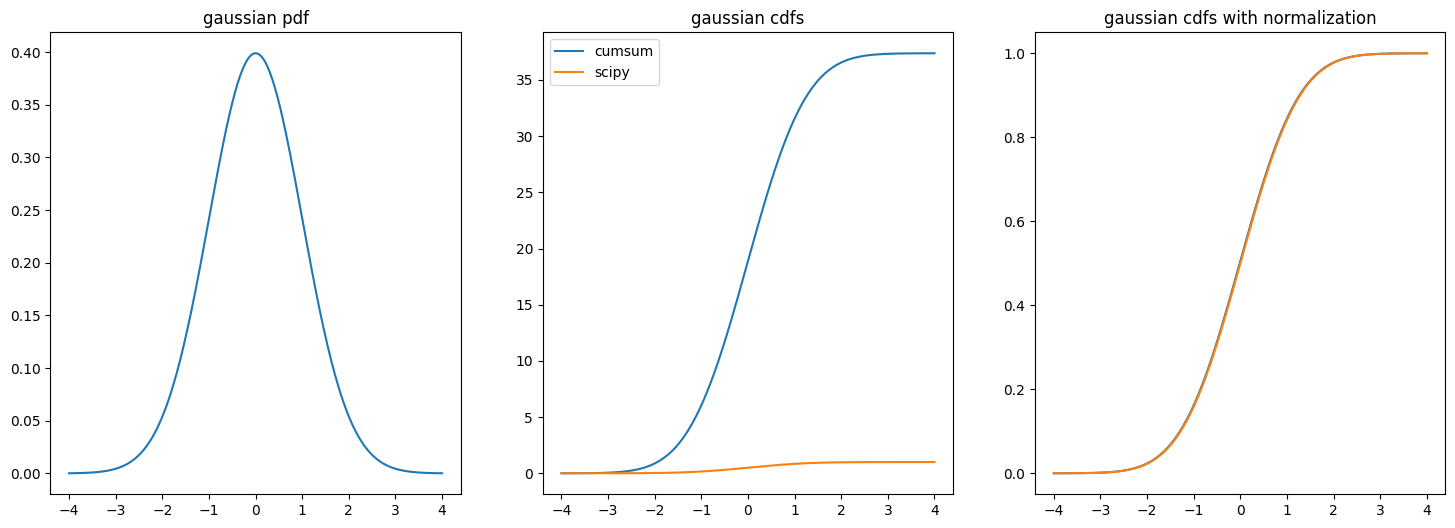

In [49]:
x = np.linspace(-4, 4, 300)
pdf = stats.norm.pdf(x)

emp_cdf = np.cumsum(pdf)
cdf = stats.norm.cdf(x)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.plot(x, pdf)
plt.title("gaussian pdf")

plt.subplot(1, 3, 2)
plt.plot(x, emp_cdf, label='cumsum')
plt.plot(x, cdf, label='scipy')
plt.legend()
plt.title("gaussian cdfs")

dx = x[1] - x[0]
norm_cdf = dx * emp_cdf

plt.subplot(1, 3, 3)
plt.plot(x, norm_cdf, label='cumsum')
plt.plot(x, cdf, label='scipy')
plt.title("gaussian cdfs with normalization")

plt.show()

- "The conclusion is that the output of scipy’s cdf functions are
normalized as expected."
- "But why does this happen? Why does the pdf function output
need to be scaled by dx while the cdf function returns the
correct probability values?"
- "The answer is that the correctly scaled pdf at any given value
of x can be computed only by knowing the x-axis spacing.
That is because its an estimate of a true pdf, which itself is
defined only for a range of numbers, not an exact number. On
the other hand, the cdf can be computed for an exact number
because it reflects the sum (integral) of all values left of that
number, from −∞ to x0 ."

# Q5

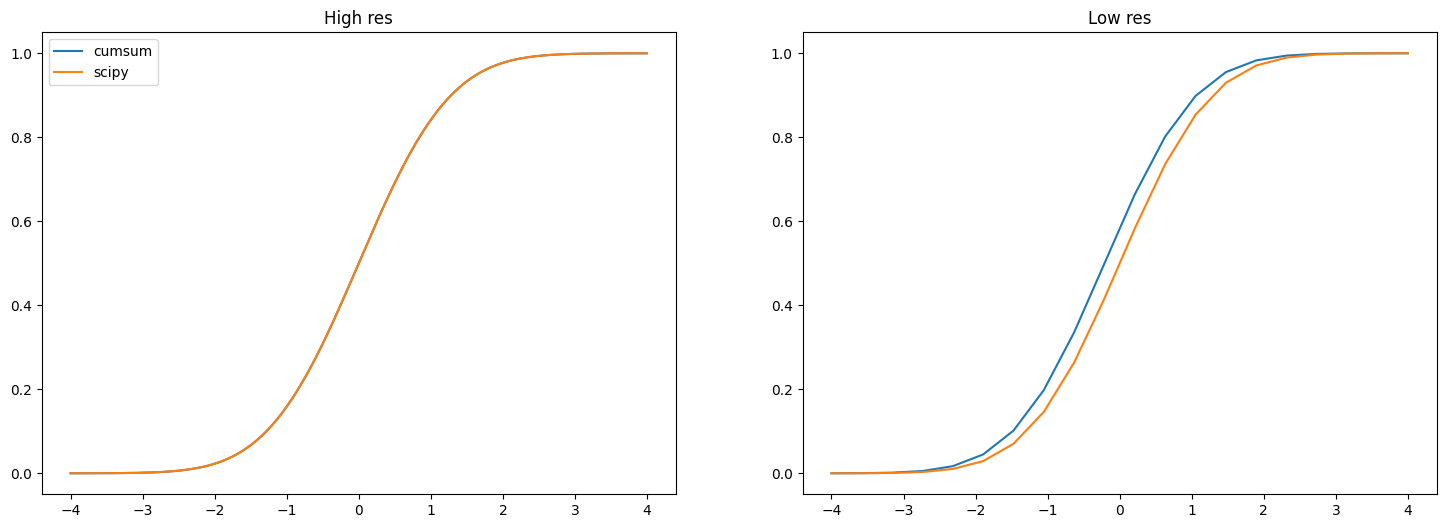

In [51]:
x1 = np.linspace(-4, 4, 5000)
pdf = stats.norm.pdf(x1)

emp_cdf1 = np.cumsum(pdf)
emp_cdf1 = (x1[1] - x1[0]) * emp_cdf1
cdf1 = stats.norm.cdf(x1)

x2 = np.linspace(-4, 4, 20)
pdf = stats.norm.pdf(x2)

emp_cdf2 = np.cumsum(pdf)
emp_cdf2 = (x2[1] - x2[0]) * emp_cdf2
cdf2 = stats.norm.cdf(x2)

plt.figure(figsize=(18, 6))

plt.subplot(1, 2, 1)
plt.plot(x1, emp_cdf1, label='cumsum')
plt.plot(x1, cdf1, label='scipy')
plt.legend()
plt.title("High res")

plt.subplot(1, 2, 2)
plt.plot(x2, emp_cdf2, label='cumsum')
plt.plot(x2, cdf2, label='scipy')
plt.title("Low res")

plt.show()

- "What causes this difference and which is correct? The answer
is that scipy’s and R’s cdf functions are more accurate. The
differences are due to numerical inaccuracies in the pdf result-
ing from a large dx. scipy and R evaluate the mathematical
cdf function based on the supplied values of x, which is more
accurate. With sufficiently high resolution, the difference be-
tween the formula-derived and empirically summed results is
negligible."

# Q6
The goal here is to compute an empirical cdf of a pdf that
is not supplied by Python or R.

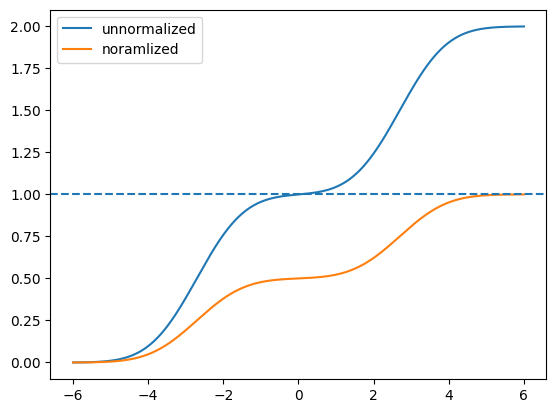

In [62]:
x1 = np.linspace(-6, 6, 1001) - 2.7
x2 = np.linspace(-6, 6, 1001) + 2.7
x = np.linspace(-6, 6, 1001)

pdf = stats.norm.pdf(x1) + stats.norm.pdf(x2)
cdf = np.cumsum(pdf) * (x[1] - x[0])

pdf_norm = pdf / np.sum(pdf)
cdf_norm = np.cumsum(pdf_norm)

cdf_norm = cdf / cdf[-1]

plt.plot(x, cdf, label='unnormalized')
plt.plot(x, cdf_norm, label='noramlized')
plt.axhline(1, linestyle='--')
plt.legend()
plt.show()

- "The problem begins with the pdf. Because we’ve summed two
individual pdfs, the result is not a true pdf even when scaled
by dx. One solution is to apply the unit sum normalization
introduced in Exercise 2. This creates a more accurate esti-
mate of a pdf, and its cumulative sum (without any additional
scaling) gives a sensible result. Another
option is to leave the pdf unnormalized and then divide the
cdf by its final value."

# Q7
The goal here is to demonstrate
that the pdf can be computed as the derivative of the cdf.

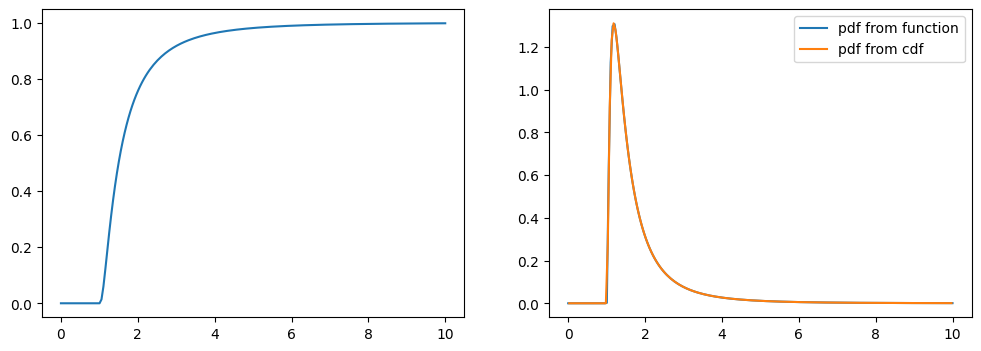

In [7]:
x = np.linspace(0, 10, 200)
dx = x[1] - x[0]

s = 1
loc = 1
scale = 0.5

cdf = stats.lognorm.cdf(x, s, loc=loc, scale=scale)

pdf1 = stats.lognorm.pdf(x, s, loc=loc, scale=scale) * dx
pdf2 = np.diff(cdf)
pdf2 /= dx
x_mid = (x[:-1] + x[1:]) / 2

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(x, cdf)

plt.subplot(1, 2, 2)
plt.plot(x, pdf1, label='pdf from function')
plt.plot(x_mid, pdf2, label='pdf from cdf')
plt.legend()
plt.show()

# Q8
This exercise will help you understand the difference between
empirical and analytical probabilities.

[232 165 103]
[0.464, 0.33, 0.206]


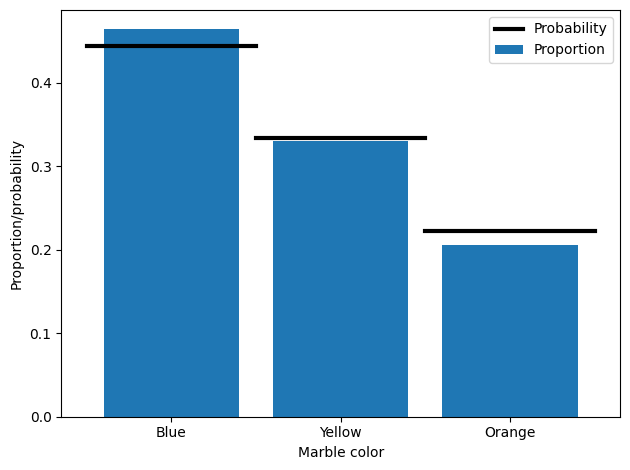

In [85]:
# colored marble counts
blue = 40
yellow = 30
orange = 20
marbles = blue + yellow + orange

# put all in a jar
jar = np.hstack((1 * np.ones(blue), 2 * np.ones(yellow), 3 * np.ones(orange)))

# now we draw 500 marbles (with replacement)
num = 500
sample = np.random.choice(jar, size=num, replace=True)
counts = np.bincount(sample.astype(int))[1:]
print(counts)
proportion = list(map(lambda i: i / num, counts))
print(proportion)

plt.bar([1, 2, 3], [proportion[0], proportion[1], proportion[2]], label='Proportion')
plt.plot([0.5, 1.5], [blue / marbles, blue / marbles], 'k', linewidth=3, label='Probability')
plt.plot([1.5, 2.5], [yellow / marbles, yellow / marbles], 'k', linewidth=3)
plt.plot([2.5, 3.5], [orange / marbles, orange / marbles], 'k', linewidth=3)

plt.xticks([1, 2, 3], labels=('Blue', 'Yellow', 'Orange'))
plt.xlabel('Marble color')
plt.ylabel('Proportion/probability')
plt.legend()

plt.tight_layout()
plt.show()

# Q9
"The proportion and probabilities in the previous exercise are
not equal, but they are "fairly close." I hope you have the
intuition that they would be a closer match if we used a larger
sample size. The Law of Large Numbers is the formalization
of that intuition."

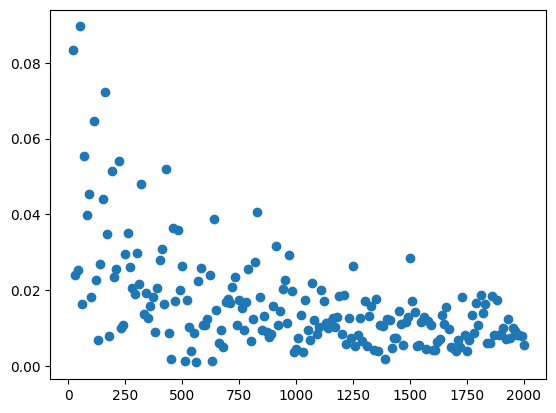

In [90]:
def rms(p, p_hat, c=3):
    p = np.array(p)
    p_hat = np.array(p_hat)
    return np.sqrt((np.sum((p - p_hat) ** 2)) / c)


rms_hist = []
for ss in np.arange(20, 2001, 10):
    sample = np.random.choice(jar, size=ss, replace=True)
    counts = np.bincount(sample.astype(int))[1:]
    proportion = list(map(lambda i: i / ss, counts))
    this_rms = rms([blue / marbles, yellow / marbles, orange / marbles], proportion)
    rms_hist.append(this_rms)
    
plt.scatter(np.arange(20, 2001, 10), rms_hist)

- "The decrease in RMS with increasing sam-
ple size is not surprising. But you might be surprised that
the RMS does not taper all the way down to zero, and you
might also be surprised at the lack of smoothness in the RMS.
Of course, all of this variability comes from the empirical pro-
portions; the analytical probabilities have nothing to do with
sample sizes or random sampling."

# Q10
The goal of this exercise is to compute empirical cumulative
proportion functions using simulated data.

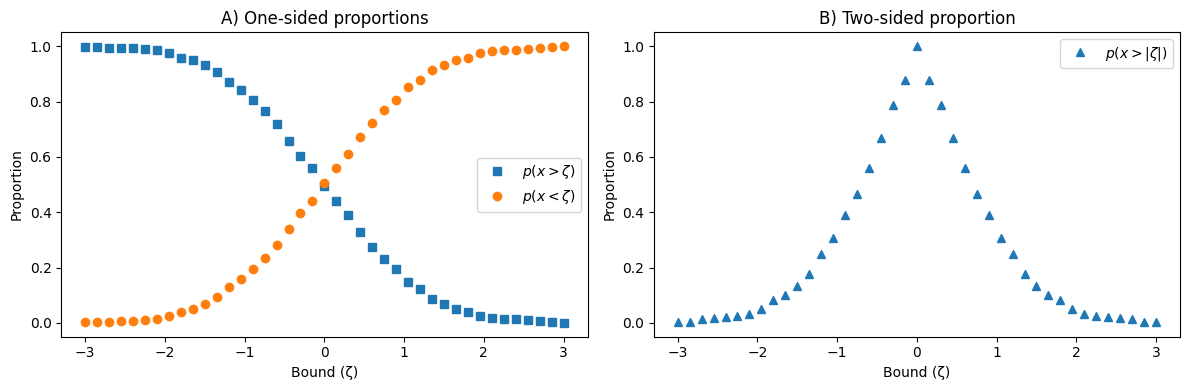

In [91]:
x = np.random.normal(size=1000)
zeta = np.linspace(-3, 3, 41)

# For a normal distribution, we’d expect most of the data to be
# above ζ = −3. Similarly, we’d expect around half of the data
# to be above ζ = 0. We can also flip this around: We’d expect
# most of the data to be below ζ = 3.
prop_above = []
prop_below = []
prop_two_sided = []

for z in zeta:
    prop_above.append(np.mean(x > z))
    prop_below.append(np.mean(x < z))
    prop_two_sided.append(np.mean(np.abs(x) > abs(z)))
    
prop_above = np.array(prop_above)
prop_below = np.array(prop_below)
prop_two_sided = np.array(prop_two_sided)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(zeta, prop_above, 's', label=r"$p(x > \zeta)$")
plt.plot(zeta, prop_below, 'o', label=r"$p(x < \zeta)$")

plt.xlabel("Bound (ζ)")
plt.ylabel("Proportion")
plt.title("A) One-sided proportions")
plt.ylim(-0.05, 1.05)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(zeta, prop_two_sided, '^', label=r"$p(x > |\zeta|)$")

plt.xlabel("Bound (ζ)")
plt.ylabel("Proportion")
plt.title("B) Two-sided proportion")
plt.ylim(-0.05, 1.05)
plt.legend()

plt.tight_layout()
plt.show()

- "Notice that the "two-tailed" proportion function in panel B
is the point-wise minimum of the two "one-sided" proportion
functions in panel A."
- "Also notice that each one-
sided proportion function is essentially an empirical estimate
of a cdf or its opposite, but the two-sided proportion function
does not look like a cdf, nor does it look like the pdf of a
normal distribution."